# 02: The mathematics of self-attention

Week 2 of the mRNA-VIP project.

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

We first work a 3-token example small enough to check by hand, then apply the implementation in `src/attention.py` to an mRNA sequence.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # run this notebook from the notebooks/ folder
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import attention as att
np.set_printoptions(precision=3, suppress=True)

## 1. A 3-token example by hand

Three tokens with 2-dimensional queries, keys and values (already projected):

In [2]:
Q = np.array([[1.0, 0.0],
              [0.0, 1.0],
              [1.0, 1.0]])
K = np.array([[1.0, 0.0],
              [0.0, 1.0],
              [1.0, 1.0]])
V = np.array([[1.0, 2.0],
              [3.0, 4.0],
              [5.0, 6.0]])
d_k = K.shape[1]

scores = Q @ K.T
print("Step 1  raw scores Q.K^T:\n", scores)
scaled = scores / np.sqrt(d_k)
print("\nStep 2  divided by sqrt(d_k) = sqrt(2):\n", scaled)
weights = att.softmax(scaled)
print("\nStep 3  softmax per row (each row sums to 1):\n", weights, "\nrow sums:", weights.sum(axis=1))
print("\nStep 4  output = weights @ V:\n", weights @ V)

Step 1  raw scores Q.K^T:
 [[1. 0. 1.]
 [0. 1. 1.]
 [1. 1. 2.]]

Step 2  divided by sqrt(d_k) = sqrt(2):
 [[0.707 0.    0.707]
 [0.    0.707 0.707]
 [0.707 0.707 1.414]]

Step 3  softmax per row (each row sums to 1):
 [[0.401 0.198 0.401]
 [0.198 0.401 0.401]
 [0.248 0.248 0.503]] 
row sums: [1. 1. 1.]

Step 4  output = weights @ V:
 [[3.    4.   ]
 [3.407 4.407]
 [3.51  4.51 ]]


Checking row 1 by hand: token 1's scaled scores are [0.707, 0, 0.707]. Then e^0.707 = 2.028 and e^0 = 1, so the weights are 2.028/5.056 = 0.401, 1/5.056 = 0.198 and 0.401. Token 1 attends equally to itself and to token 3 (both share its first dimension) and least to token 2.

## 2. Encode an mRNA sequence

In [3]:
sequence = att.DEFAULT_SEQUENCE
X = att.encode_sequence(sequence)
print(sequence, "->", X.shape, "(seq_len, embed_dim)")
print("Embedding of A:", att.EMBEDDING_TABLE["A"])
try:
    att.encode_sequence("ACGX")
except att.InvalidSequenceError as err:
    print("Rejected:", err)

ACGUACGUACGGCUA -> (15, 8) (seq_len, embed_dim)
Embedding of A: [ 0.305 -1.04   0.75   0.941 -1.951 -1.302  0.128 -0.316]
Rejected: Invalid nucleotide(s): 'X' at position 4. Allowed: A, C, G, U.


## 3. Attention over the sequence

weights: (15, 15)  output: (15, 8)
All rows sum to 1: True


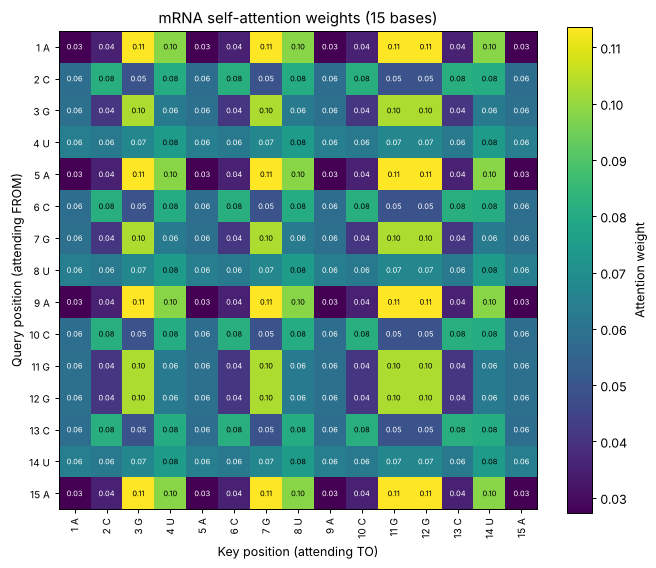

In [4]:
weights, output = att.self_attention(X, att.init_projection_weights())
print("weights:", weights.shape, " output:", output.shape)
print("All rows sum to 1:", np.allclose(weights.sum(axis=1), 1.0))
att.attention_figure(weights, sequence);

Rows for the same base are identical because the embedding depends only on the base, not its position. The strongest pairs, measured as mean weight per query/key pair (uniform would be 1/15 = 0.067):

In [5]:
dict(list(att.base_pair_attention(weights, sequence).items())[:5])

{'A->G': 0.11365286558261015, 'G->G': 0.10290168409101347, 'A->U': 0.09845182870943502, 'C->C': 0.08162675690350679, 'C->U': 0.08090911367486199}

## 4. Why the weight scale matters

The PRD template multiplies random weights by 0.1. That makes every score close to zero, and softmax of near-equal scores is almost uniform, so the heatmap goes flat. Xavier scaling (std = 1/sqrt(embed_dim)) keeps the scores around unit size.

In [6]:
rng = np.random.default_rng(1)
tiny = att.ProjectionWeights(*(rng.standard_normal((8, 8)) * 0.1 for _ in range(3)))
w_tiny, _ = att.self_attention(X, tiny)
w_xavier, _ = att.self_attention(X, att.init_projection_weights())
print(f"x0.1 weights:   min {w_tiny.min():.3f}  max {w_tiny.max():.3f}   (uniform = {1/15:.3f})")
print(f"Xavier weights: min {w_xavier.min():.3f}  max {w_xavier.max():.3f}")

x0.1 weights:   min 0.063  max 0.071   (uniform = 0.067)
Xavier weights: min 0.027  max 0.114


## 5. Adding positional encoding

With sinusoidal positions added to the embeddings, identical bases at different positions no longer behave identically:

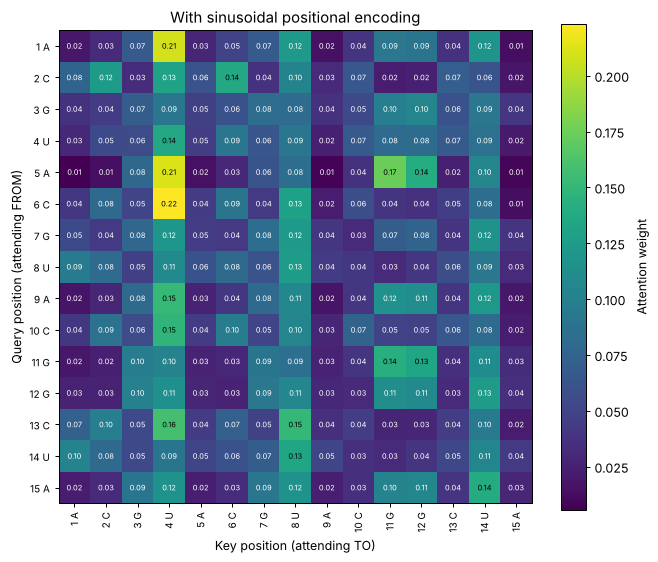

In [7]:
w_pos, _ = att.self_attention(att.encode_sequence(sequence, positional=True))
att.attention_figure(w_pos, sequence, title="With sinusoidal positional encoding");

## 6. Bonus: multi-head attention

Two heads, each with its own random Q/K/V projections (d_k = 4), learn different patterns; their outputs are concatenated back to width 8.

concatenated output: (15, 8)


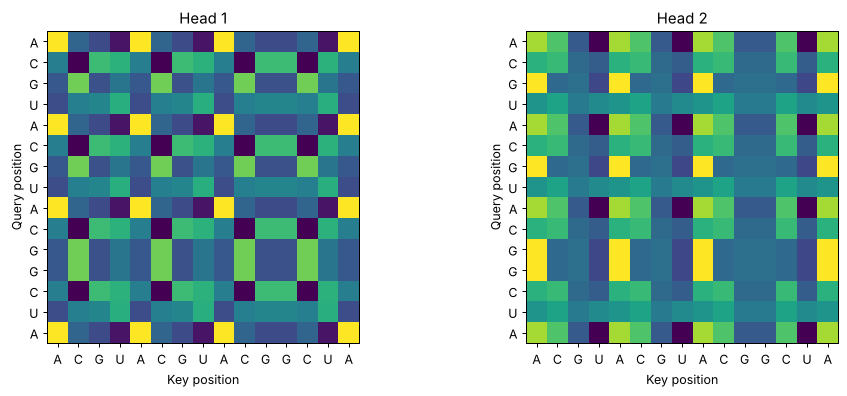

In [8]:
heads, mh_output = att.multi_head_attention(X, n_heads=2)
print("concatenated output:", mh_output.shape)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for i, (ax, w) in enumerate(zip(axes, heads)):
    ax.imshow(w, cmap="viridis")
    ax.set_title(f"Head {i + 1}")
    ax.set_xticks(range(len(sequence))); ax.set_xticklabels(list(sequence))
    ax.set_yticks(range(len(sequence))); ax.set_yticklabels(list(sequence))
    ax.set_xlabel("Key position"); ax.set_ylabel("Query position")
fig.tight_layout()

## 7. Cross-check against PyTorch

In [9]:
try:
    w_torch, _ = att.self_attention_torch(X, att.init_projection_weights())
    print("PyTorch result matches NumPy:", np.allclose(w_torch, weights))
except ImportError:
    print("PyTorch is not installed in this environment; install requirements.txt to run this check.")

PyTorch is not installed in this environment; install requirements.txt to run this check.
